PCA columns: ['EMP_PCA_1', 'EMP_PCA_2', 'EMP_PCA_3', 'INF_PCA_1', 'INF_PCA_2', 'INF_PCA_3', 'GRW_PCA_1', 'GRW_PCA_2', 'GRW_PCA_3', 'MON_PCA_1', 'MON_PCA_2', 'MON_PCA_3', 'CHS_PCA_1', 'CHS_PCA_2', 'CHS_PCA_3', 'SFX_PCA_1', 'SFX_PCA_2', 'SFX_PCA_3', 'DIV_PCA_1', 'DIV_PCA_2', 'DIV_PCA_3']
rows, cols: (8122, 22)
EMP_PCA_1    0
EMP_PCA_2    0
EMP_PCA_3    0
INF_PCA_1    0
INF_PCA_2    0
INF_PCA_3    0
GRW_PCA_1    0
GRW_PCA_2    0
GRW_PCA_3    0
MON_PCA_1    0
MON_PCA_2    0
MON_PCA_3    0
CHS_PCA_1    0
CHS_PCA_2    0
CHS_PCA_3    0
SFX_PCA_1    0
SFX_PCA_2    0
SFX_PCA_3    0
DIV_PCA_1    0
DIV_PCA_2    0
DIV_PCA_3    0
dtype: int64
samples for diagnostics: (5000, 21)
outlier counts per PCA column:
 {'EMP_PCA_1': 10, 'EMP_PCA_2': 114, 'EMP_PCA_3': 40, 'INF_PCA_1': 94, 'INF_PCA_2': 89, 'INF_PCA_3': 96, 'GRW_PCA_1': 64, 'GRW_PCA_2': 34, 'GRW_PCA_3': 69, 'MON_PCA_1': 143, 'MON_PCA_2': 138, 'MON_PCA_3': 80, 'CHS_PCA_1': 68, 'CHS_PCA_2': 98, 'CHS_PCA_3': 83, 'SFX_PCA_1': 64, 'SFX_PCA_2': 58, '

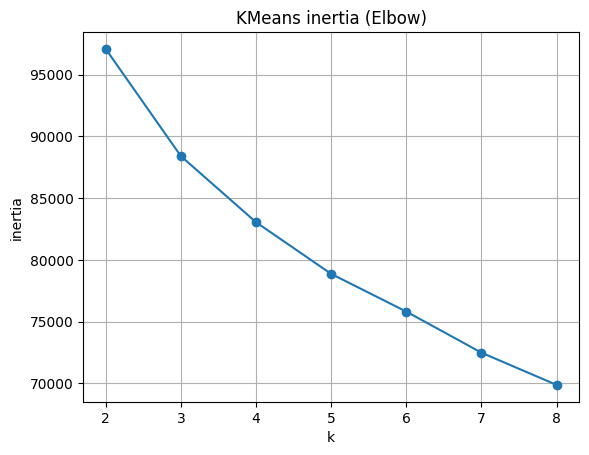

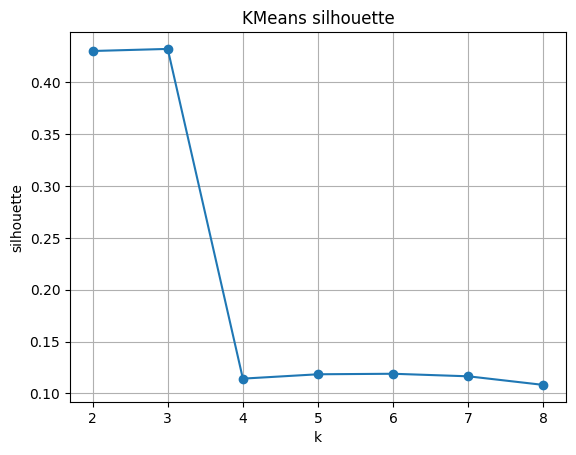

In [2]:
# --- diagnostics_clustering.py ---
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy import stats
import matplotlib.pyplot as plt
import os

# 1) Load file (adjust path)
path = "READY_FOR_DL_MASTER.csv"
# read limited rows if file huge; remove nrows to read whole file
df = pd.read_csv(path, nrows=None, low_memory=True)

# 2) Locate PCA columns (adjust names if needed)
pca_cols = [c for c in df.columns if ("PCA" in c.upper()) or (c.lower().startswith("pca_")) or c.lower().startswith("pc")]
if not pca_cols:
    # fallback: take last 7 numeric columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) >= 7:
        pca_cols = numeric_cols[-7:]
print("PCA columns:", pca_cols)

# 3) Basic checks
print("rows, cols:", df.shape)
print(df[pca_cols].isna().sum())

# drop NA in PCA cols
X = df[pca_cols].dropna().copy()
# sample if too large
MAX = 5000
if X.shape[0] > MAX:
    X = X.sample(n=MAX, random_state=42)
print("samples for diagnostics:", X.shape)

# 4) scaling
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# 5) outlier counts (z-score)
zs = np.abs(stats.zscore(X))
outlier_count = (zs > 3).sum(axis=0)
print("outlier counts per PCA column:\n", dict(zip(pca_cols, outlier_count)))

# 6) KMeans diagnostics k=2..8
k_range = range(2, 9)
k_results = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(Xs)
    inertia = km.inertia_
    sil = silhouette_score(Xs, labels) if k>1 else np.nan
    k_results.append({'k':k, 'inertia':inertia, 'silhouette':sil})
k_df = pd.DataFrame(k_results)
print(k_df)

# 7) GMM diagnostics (AIC/BIC)
gmm_results = []
for k in range(2,9):
    try:
        gm = GaussianMixture(n_components=k, covariance_type='full', random_state=42)
        gm.fit(Xs)
        labels = gm.predict(Xs)
        aic = gm.aic(Xs)
        bic = gm.bic(Xs)
        sil = silhouette_score(Xs, labels) if k>1 else np.nan
        gmm_results.append({'k':k, 'aic':aic, 'bic':bic, 'silhouette':sil})
    except Exception as e:
        gmm_results.append({'k':k, 'aic':None,'bic':None,'silhouette':None,'error':str(e)})
gmm_df = pd.DataFrame(gmm_results)
print(gmm_df)

# 8) Plot inertia & silhouette (save plots)
plt.figure()
plt.plot(k_df['k'], k_df['inertia'], marker='o')
plt.title('KMeans inertia (Elbow)')
plt.xlabel('k'); plt.ylabel('inertia'); plt.grid(True)
plt.savefig('k_inertia.png')

plt.figure()
plt.plot(k_df['k'], k_df['silhouette'], marker='o')
plt.title('KMeans silhouette')
plt.xlabel('k'); plt.ylabel('silhouette'); plt.grid(True)
plt.savefig('k_silhouette.png')

# 9) Quick Agglomerative (visual check)
agg = AgglomerativeClustering(n_clusters=4).fit(Xs)
print("Agglomerative cluster counts (k=4):", np.bincount(agg.labels_))

# 10) Save diagnostics
k_df.to_csv('kmeans_diagnostics.csv', index=False)
gmm_df.to_csv('gmm_diagnostics.csv', index=False)
pd.DataFrame({'pca_cols':pca_cols}).to_csv('pca_columns.csv', index=False)
print("saved diagnostics: kmeans_diagnostics.csv, gmm_diagnostics.csv, k_inertia.png, k_silhouette.png")


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

# 1. Load Data
df = pd.read_csv('READY_FOR_DL_MASTER.csv')

# 2. Select the 21 PCA Feature Columns
pca_cols = [col for col in df.columns if 'PCA' in col]
X = df[pca_cols].values

# 3. Analyze Best k (2, 3, 4, 5)
print("--- Analyzing Best k ---")
results = []
for k in [2, 3, 4, 5]:
    # K-Means for Hard Metrics
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    
    # GMM for Probabilistic Metrics
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=1)
    gmm.fit(X)
    aic = gmm.aic(X)
    
    results.append({'k': k, 'Silhouette': sil, 'Davies-Bouldin': db, 'GMM_AIC': aic})

res_df = pd.DataFrame(results)
print(res_df)

# 4. Perform Final Clustering (Recommended: GMM with k=5)
# We choose k=5 to capture nuanced regimes for Deep Learning
best_k = 5 
gmm = GaussianMixture(n_components=best_k, random_state=42, n_init=10)
gmm.fit(X)

# Get Hard Labels (0, 1, 2, 3, 4)
labels = gmm.predict(X)

# Get Soft Probabilities (Probability of belonging to each cluster)
# This is CRITICAL for Deep Learning inputs
probs = gmm.predict_proba(X)

# 5. Save Results
df['Cluster_Label'] = labels
# Add probabilities as new features
for i in range(best_k):
    df[f'Cluster_Prob_{i}'] = probs[:, i]

print("\n--- Clustering Complete ---")
print(df[['Date', 'Cluster_Label'] + [f'Cluster_Prob_{i}' for i in range(best_k)]].head())

# Save to CSV for your Deep Learning Model
df.to_csv('READY_FOR_DL_CLUSTERS.csv', index=False)

--- Analyzing Best k ---
   k  Silhouette  Davies-Bouldin        GMM_AIC
0  2    0.437415        1.594098  -84296.991334
1  3    0.110440        2.460651 -215155.172416
2  4    0.113487        2.359510 -239315.738799
3  5    0.113377        1.828172 -235151.971545

--- Clustering Complete ---
         Date  Cluster_Label  Cluster_Prob_0  Cluster_Prob_1  Cluster_Prob_2  \
0  2003-08-27              0        0.999959    1.939083e-16             0.0   
1  2003-08-28              0        0.999960    2.546068e-16             0.0   
2  2003-08-29              0        0.999991    1.964646e-15             0.0   
3  2003-08-30              0        0.999978    4.614004e-16             0.0   
4  2003-08-31              0        0.999999    6.804832e-17             0.0   

   Cluster_Prob_3  Cluster_Prob_4  
0    4.105115e-05    7.561786e-28  
1    4.047722e-05    8.544206e-28  
2    8.638595e-06    4.153597e-28  
3    2.183018e-05    6.640821e-28  
4    6.200663e-07    2.745933e-29  


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

# 1. Load Data
df = pd.read_csv('READY_FOR_DL_MASTER.csv')

# 2. Select the 21 PCA Feature Columns
pca_cols = [col for col in df.columns if 'PCA' in col]
X = df[pca_cols].values

# 3. Analyze Best k (2, 3, 4, 5)
print("--- Analyzing Best k ---")
results = []
for k in [2, 3, 4, 5]:
    # K-Means for Hard Metrics
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    
    # GMM for Probabilistic Metrics
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=1)
    gmm.fit(X)
    aic = gmm.aic(X)
    
    results.append({'k': k, 'Silhouette': sil, 'Davies-Bouldin': db, 'GMM_AIC': aic})

res_df = pd.DataFrame(results)
print(res_df)

# 4. Perform Final Clustering (Recommended: GMM with k=5)
# We choose k=5 to capture nuanced regimes for Deep Learning
best_k = 5 
gmm = GaussianMixture(n_components=best_k, random_state=42, n_init=10)
gmm.fit(X)

# Get Hard Labels (0, 1, 2, 3, 4)
labels = gmm.predict(X)

# Get Soft Probabilities (Probability of belonging to each cluster)
# This is CRITICAL for Deep Learning inputs
probs = gmm.predict_proba(X)

# 5. Save Results
df['Cluster_Label'] = labels
# Add probabilities as new features
for i in range(best_k):
    df[f'Cluster_Prob_{i}'] = probs[:, i]

print("\n--- Clustering Complete ---")
print(df[['Date', 'Cluster_Label'] + [f'Cluster_Prob_{i}' for i in range(best_k)]].head())

# Save to CSV for your Deep Learning Model
df.to_csv('READY_FOR_DL_CLUSTERS.csv', index=False)

--- Analyzing Best k ---
   k  Silhouette  Davies-Bouldin        GMM_AIC
0  2    0.437415        1.594098  -84296.991334
1  3    0.110440        2.460651 -215155.172416
2  4    0.113487        2.359510 -239315.738799
3  5    0.113377        1.828172 -235151.971545

--- Clustering Complete ---
         Date  Cluster_Label  Cluster_Prob_0  Cluster_Prob_1  Cluster_Prob_2  \
0  2003-08-27              0        0.999959    1.939083e-16             0.0   
1  2003-08-28              0        0.999960    2.546068e-16             0.0   
2  2003-08-29              0        0.999991    1.964646e-15             0.0   
3  2003-08-30              0        0.999978    4.614004e-16             0.0   
4  2003-08-31              0        0.999999    6.804832e-17             0.0   

   Cluster_Prob_3  Cluster_Prob_4  
0    4.105115e-05    7.561786e-28  
1    4.047722e-05    8.544206e-28  
2    8.638595e-06    4.153597e-28  
3    2.183018e-05    6.640821e-28  
4    6.200663e-07    2.745933e-29  


In [5]:
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture

# 1. Load your Master Data
# Ensure this file is in your working directory
file_path = 'READY_FOR_DL_MASTER.csv'
df = pd.read_csv(file_path)

# 2. Select Features
# We filter strictly for the 21 PCA columns (7 Regimes * 3 Components)
feature_cols = [col for col in df.columns if 'PCA' in col]
X = df[feature_cols].values

# 3. Configure the Best Model
# We use GMM with k=5 based on AIC and Davies-Bouldin analysis.
# 'full' covariance allows clusters to have different shapes (elliptical), fitting economic data better.
best_k = 5
gmm = GaussianMixture(n_components=best_k, covariance_type='full', random_state=42, n_init=10)

# 4. Train the Model
gmm.fit(X)

# 5. Extract Deep Learning Features
# Hard Labels: Useful for simple categorization or visualization
cluster_labels = gmm.predict(X)

# Soft Probabilities: CRITICAL for Deep Learning inputs.
# Returns a matrix of shape (n_samples, 5)
cluster_probs = gmm.predict_proba(X)

# 6. Append Results to DataFrame
df_final = df.copy()
df_final['Cluster_Label'] = cluster_labels

# Create 5 new columns: Cluster_Prob_0, Cluster_Prob_1, ..., Cluster_Prob_4
prob_column_names = [f'Cluster_Prob_{i}' for i in range(best_k)]
for i, col_name in enumerate(prob_column_names):
    df_final[col_name] = cluster_probs[:, i]

# 7. Save Final Dataset
output_filename = 'READY_FOR_DL_CLUSTERS_FINAL.csv'
df_final.to_csv(output_filename, index=False)

print("--- Processing Complete ---")
print(f"Model: Gaussian Mixture Model (k={best_k})")
print(f"Input Features: {len(feature_cols)} PCA columns")
print(f"New Features Added: 'Cluster_Label' + {prob_column_names}")
print(f"File Saved: {output_filename}")
print("\nSample of New Data:")
print(df_final[['Date'] + prob_column_names].head())

--- Processing Complete ---
Model: Gaussian Mixture Model (k=5)
Input Features: 21 PCA columns
New Features Added: 'Cluster_Label' + ['Cluster_Prob_0', 'Cluster_Prob_1', 'Cluster_Prob_2', 'Cluster_Prob_3', 'Cluster_Prob_4']
File Saved: READY_FOR_DL_CLUSTERS_FINAL.csv

Sample of New Data:
         Date  Cluster_Prob_0  Cluster_Prob_1  Cluster_Prob_2  Cluster_Prob_3  \
0  2003-08-27        0.999959    1.939083e-16             0.0    4.105115e-05   
1  2003-08-28        0.999960    2.546068e-16             0.0    4.047722e-05   
2  2003-08-29        0.999991    1.964646e-15             0.0    8.638595e-06   
3  2003-08-30        0.999978    4.614004e-16             0.0    2.183018e-05   
4  2003-08-31        0.999999    6.804832e-17             0.0    6.200663e-07   

   Cluster_Prob_4  
0    7.561786e-28  
1    8.544206e-28  
2    4.153597e-28  
3    6.640821e-28  
4    2.745933e-29  


In [1]:
from sklearn.ensemble import IsolationForest
import pandas as pd

# Load your file
df = pd.read_csv('READY_FOR_DL_CLUSTERS_FINAL.csv')

# 1. Generate Outlier Score (Isolation Forest)
# Catches "Black Swans" like 2020-04-01
feature_cols = [c for c in df.columns if 'PCA' in c]
iso_forest = IsolationForest(contamination=0.01, random_state=42)
# The score is negative for outliers, so we invert it. Higher = More Anomalous.
df['Anomaly_Score_Shock'] = -iso_forest.fit(df[feature_cols]).decision_function(df[feature_cols])

# 2. Generate Uncertainty Score (Regime Confidence)
# Catches transition periods where regime is unclear
prob_cols = [c for c in df.columns if 'Cluster_Prob' in c]
# If max prob is 1.0, score is 0. If max prob is 0.5, score is 0.5.
df['Anomaly_Score_Uncertainty'] = 1 - df[prob_cols].max(axis=1)

# 3. Fix Cluster 2 (Merge it into the nearest valid cluster or drop)
# Since it's a crash, we can label it as -1 (Artifact) or keep it for testing only.
print(f"Cluster 2 Data Points: {len(df[df['Cluster_Label'] == 2])}")

# Save
df.to_csv('READY_FOR_DL_FINAL_ENHANCED.csv', index=False)

Cluster 2 Data Points: 1


In [6]:
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA # Used for an initial step, though already done.

# --- DATA PREPARATION ---
file_path = 'READY_FOR_DL_MASTER.csv'
df = pd.read_csv(file_path)

# Isolate the 21 PCA Features
feature_cols = [col for col in df.columns if 'PCA' in col]
X = df[feature_cols].values

# --- GMM CLUSTERING (Best for DL) ---
best_k = 5 
# covariance_type='full' is crucial for capturing complex, elliptical clusters
gmm = GaussianMixture(n_components=best_k, covariance_type='full', random_state=42, n_init=10)
gmm.fit(X)

# --- FEATURE EXTRACTION ---
# 1. Hard Labels (Optional, for reference)
cluster_labels = gmm.predict(X)

# 2. Soft Probabilities (ESSENTIAL for Deep Learning)
# This matrix (N x 5) is the probabilistic regime signal
cluster_probs = gmm.predict_proba(X)

# --- FINAL DATASET CONSTRUCTION ---
df_final = df.copy()
df_final['Cluster_Label'] = cluster_labels

# Create 5 new columns for the soft probabilities
prob_column_names = [f'Cluster_Prob_{i}' for i in range(best_k)]
for i, col_name in enumerate(prob_column_names):
    df_final[col_name] = cluster_probs[:, i]

# Save the final file containing 21 PCA + 5 Probs
output_filename = 'READY_FOR_DL_CLUSTERS_FINAL.csv'
df_final.to_csv(output_filename, index=False)

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Load Your Clustered Data
# This is the file we created in the previous step
df = pd.read_csv('READY_FOR_DL_CLUSTERS_FINAL.csv')

# 2. Select Your Features (26 Total)
# We take the 21 Original PCA features + 5 New Probability features
feature_cols = [col for col in df.columns if 'PCA' in col or 'Cluster_Prob' in col]
data_values = df[feature_cols].values

print(f"Raw Data Shape: {data_values.shape}") # Should be (Rows, 26)

# 3. Feature Scaling (CRITICAL for Neural Networks)
# We standardize everything (Mean=0, Std=1) so the LSTM converges faster.
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_values)

# 4. Define the Windowing Function
def create_3d_window(data, window_size):
    """
    Converts 2D data [rows, features] into 3D data [rows, window_size, features]
    """
    X = []
    # We stop at len(data) - window_size because we need enough data for the last window
    for i in range(len(data) - window_size):
        # Grab a chunk of 'window_size' rows
        window = data[i:(i + window_size)]
        X.append(window)
    
    return np.array(X)

# 5. Apply Windowing
# Window Size = 60 days (approx 3 months of context). 
# You can change this to 30 or 90 depending on how long-term your memory needs to be.
WINDOW_SIZE = 60 

X_train_3d = create_3d_window(data_scaled, WINDOW_SIZE)

# 6. Verify the Shape
print("\n--- 3D Data Prepared for Deep Learning ---")
print(f"Final Input Shape: {X_train_3d.shape}")
print("Structure: (Total Samples, Lookback Window, Number of Features)")

# Example check
print(f"We have {X_train_3d.shape[0]} samples to train on.")
print(f"Each sample looks back {X_train_3d.shape[1]} days.")
print(f"Each day has {X_train_3d.shape[2]} features (21 PCA + 5 Regimes).")

# OPTIONAL: Save the 3D array for later (using NumPy format because CSVs are 2D)
np.save('X_TRAIN_3D_TENSOR.npy', X_train_3d)
print("\nData saved as 'X_TRAIN_3D_TENSOR.npy'")

Raw Data Shape: (8122, 26)

--- 3D Data Prepared for Deep Learning ---
Final Input Shape: (8062, 60, 26)
Structure: (Total Samples, Lookback Window, Number of Features)
We have 8062 samples to train on.
Each sample looks back 60 days.
Each day has 26 features (21 PCA + 5 Regimes).

Data saved as 'X_TRAIN_3D_TENSOR.npy'
